# Unsupervised Learning

## Import

In [ ]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn import metrics
from sklearn.metrics import silhouette_score
from scipy.spatial.distance import cdist
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import TruncatedSVD
from sklearn.mixture import GaussianMixture
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import DBSCAN
from scipy.cluster.hierarchy import dendrogram, linkage

## Preprocess

Le but de cette division nous permet de prendre le CSV initial et d'en normaliser les données afin de pouvoir les faire analyser par l'IA plus efficacement.

On va créer un nouveau CSV avec 3 colonnes : chiffre couleur et phrase(symptome)

Le but va être de séparer les données du CSV inital qui ne possède pas de labals. Pour ceci, on va séparer les données aux virgules.
On enlève les guillemets qui ne sont pas toujours présente pour n'avoir que le symptôme propre sans avoir d'élément parasites.

In [85]:
df = pd.DataFrame(columns=["chiffre", "couleur", "phrase"])

with open("Student_Dataset.csv", "r", encoding="utf-8") as fichier:

    for ligne in fichier:
        ligne = ligne.strip()

        chiffre, phrase = ligne.split(",", 1)

        if "0x000000" in phrase:
            couleur, symptome = phrase.split(",", 1)
            symptome = symptome.replace('"', "")
            df.loc[len(df)] = [chiffre, couleur, symptome]

        else :
            phrase = phrase.replace('"', "")
            df.loc[len(df)] = [chiffre, "", phrase]

df.to_csv("Nouveau_Dataset.csv", index=False)

## Vérification

Pour vérifier que tout à été bien ajouté correctement, on vérifie la longueur des trois colonnes.

Et qu'il n'y est pas de vide dans les colonnes chiffre et phrase

In [86]:
print("Longueur de la colonne chiffre :", len(df["chiffre"]))
print("Longueur de la colonne couleur :", len(df["couleur"]))
print("Longueur de la colonne phrase :", len(df["phrase"]))

for k in df["chiffre"]:
    if k == "" or k == None:
        print("Erreur de valeur")

for k in df["phrase"]:
    if k == "" or k == None:
        print("Erreur de valeur")

Longueur de la colonne chiffre : 1011
Longueur de la colonne couleur : 1011
Longueur de la colonne phrase : 1011


## TF-IDF Vectorizer

Pour pouvoir entrainer notre IA, on va trasformer tous les mots en vecteur, qui seront compréhensible par notre IA.

On obtient également le nombre de mots différents parmi les 1011 lignes composant le dataset.

Pour éviter d'être embetté par des mots non pertinents au problème, on vectorise en enlevant les stop-words(the, a ...) afin de ne garder que des mots relatifs aux symptomes.

In [87]:
vectorizer = TfidfVectorizer(stop_words='english')
X = vectorizer.fit_transform(df["phrase"])
noms = vectorizer.get_feature_names_out()
print(X.shape)

(1011, 2135)


## TruncatedSVD

In [88]:
resultats = []

for n_comp in range(100, 301, 100):
    svd = TruncatedSVD(n_components=n_comp, random_state=42)
    X_reduced = svd.fit_transform(X)

    for k in range(2, 40):
        kmeans = KMeans(n_clusters=k, random_state=42, n_init="auto").fit(X_reduced)
        score = silhouette_score(X_reduced, kmeans.labels_)
        resultats.append((n_comp, k, score))

df_resultats = pd.DataFrame(resultats, columns=["n_components", "k", "silhouette"])

print(df_resultats)

meilleur = df_resultats.loc[df_resultats["silhouette"].idxmax()]
print("Meilleure combinaison (sans contrainte) :\n", meilleur)

best_n_comp = int(meilleur["n_components"])
best_k = int(meilleur["k"])

svd_final = TruncatedSVD(n_components=best_n_comp, random_state=42)
X_reduced_final = svd_final.fit_transform(X)

print(f"Variance expliquée avec {best_n_comp} composantes :", svd_final.explained_variance_ratio_.sum())

     n_components   k  silhouette
0             100   2    0.027318
1             100   3    0.023813
2             100   4    0.031847
3             100   5    0.036213
4             100   6    0.035924
..            ...  ..         ...
109           300  35    0.030299
110           300  36    0.030230
111           300  37    0.028496
112           300  38    0.027837
113           300  39    0.030142

[114 rows x 3 columns]
Meilleure combinaison (sans contrainte) :
 n_components    100.000000
k                19.000000
silhouette        0.059847
Name: 17, dtype: float64
Variance expliquée avec 100 composantes : 0.3825975258009121


## Loss Function (Unsupervised)

Dans notre partie non supervisée, la fonction de perte (ou loss function) s'appelle l'inertie. Elle calcule la somme des distances au carré entre chaque point de donnée et le centre du cluster auquel il est assigné. L'algorithme KMeans cherche constamment à minimiser cette valeur à chaque itération pour rendre les groupes les plus compacts et homogènes possible. Concrètement, nous l'utilisons avec la Elbow Method pour identifier le nombre optimal de clusters, c'est-à-dire le point où la baisse de l'inertie commence à ralentir. Ainsi, une inertie plus faible garantit que les symptômes regroupés dans un même cluster partagent des similarités sémantiques fortes et médicalement cohérentes.

## Elbow Method (Inertias)

Ensuite, nous faisons la "Elbow Method" (Méthode du coude) afin de déterminer une zone de valeurs idéales pour trouver notre nombre de cluster le plus efficace.

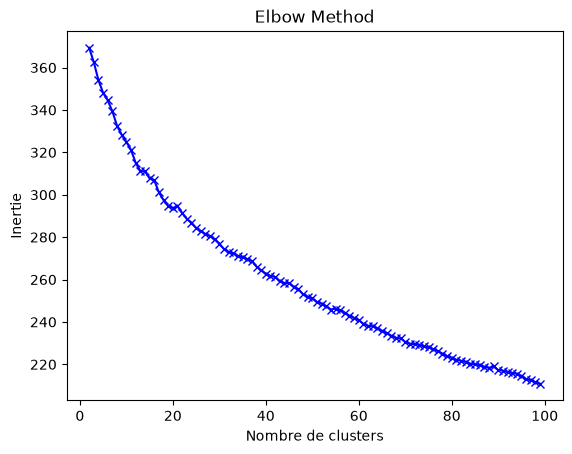

In [89]:

inertias = []
K = range(2, 100)

for k in K:
    kmeanModel = KMeans(n_clusters=k, random_state=42).fit(X_reduced_final)
    inertias.append(kmeanModel.inertia_)

plt.plot(K, inertias, 'bx-')
plt.xlabel('Nombre de clusters')
plt.ylabel('Inertie')
plt.title("Elbow Method")
plt.show()

Pour obtenir plus de précision, nous utilisons une silhouette score afin d'avoir une meilleure précision sur le nombre de clusters idéal pour regrouper nos différents mots.

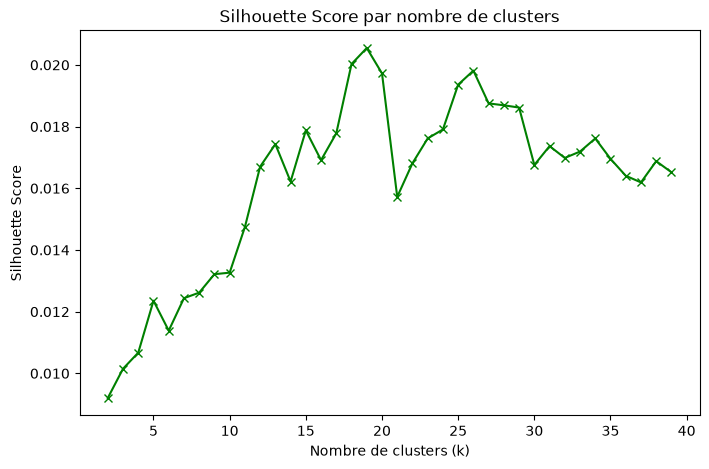

In [90]:
silhouette_scores = []
K2 = range(2, 40)

for k in K2:
    kmeanModel = KMeans(n_clusters=k, random_state=42).fit(X_reduced_final)
    score = silhouette_score(X, kmeanModel.labels_)
    silhouette_scores.append(score)

plt.figure(figsize=(8, 5))
plt.plot(K2, silhouette_scores, 'gx-')
plt.xlabel('Nombre de clusters (k)')
plt.ylabel('Silhouette Score')
plt.title("Silhouette Score par nombre de clusters")
plt.show()

## Première conclusion

Grâce à notre vérifacation entre le nombre de components de TruncatedSVD et le nombre de clusters, on en vient à la conclusion que le meilleur assemblages est 100 components avec 19 clusters pour un score de 0.05, et une variance de 0.3825.

On peut d'ailleurs vérifier ceci à l'aide de deux graphiques générés par une Elbow method et un silhouette score. Ils donnent chacun correlation sur 
ce résultat de 19 clusters.

Ce chiffre bien que bas reste tout de même assez élévé. En effet, notre but et de trouver un moyen de regrouper les patients de la meilleur façon, signifiant qu'il ne faut pas avoir un nombre de groupe trop bas sous peine d'avoir des symptôme trop éloignés au sein d'un même groupe. Mais il ne faut pas non plus un trop grand nombre de groupe, qui obligerai certain à avoir plusieurs fois le même type de symptômes.

Au delà de ça, on se doute bien qu'un médecin ne va pas faire 100/200 groupes de personnes qui serait absolument impossible à gérer facilement. 

La présence d'un pic à 19 clusters de notre coefficient de silhouette va également plus ou moins dans ce sens, car le groupage des différents individus en 19 groupes reste cohérent avec ce qui peut se faire dans la réalité.

Malgré tout, nous décidons de faire d'autres vérification pour vérifier l'efficacité de ce nombre de clusters.

## Clustering

On met donc notre nombre de cluster à 19, et on regroupe nos mots dans ceux-ci. 

On vérifie ensuite que nous obtenons un regroupement assez précis et adhéquat entre les éléments.

In [91]:
k_final = best_k

kmeans = KMeans(n_clusters=k_final, random_state=42, n_init="auto").fit(X_reduced_final)

centres_originaux = svd_final.inverse_transform(kmeans.cluster_centers_)

for k in range(k_final):
    indices = centres_originaux[k].argsort()[-10:][::-1]
    print(f"**** Cluster n°{k} ****")
    for l in indices:
        print(noms[l])
    print()

**** Cluster n°0 ****
elbow
arm
brings
feels
palm
forearm
ache
outer
stiff
turning

**** Cluster n°1 ****
ankle
wrist
sore
outer
little
finger
foot
pushing
heel
walking

**** Cluster n°2 ****
pain
starts
head
throbbing
feel
worse
gets
light
like
vision

**** Cluster n°3 ****
ear
pain
fever
slight
cold
hear
right
sound
hearing
feel

**** Cluster n°4 ****
hot
blister
red
skin
small
touched
swollen
area
hand
tender

**** Cluster n°5 ****
throat
nose
didn
mild
cold
runny
cough
sore
felt
fever

**** Cluster n°6 ****
felt
took
day
mild
headache
congestion
cough
evening
nose
slight

**** Cluster n°7 ****
toe
shoes
foot
pushing
big
standing
walk
joint
uncomfortable
brings

**** Cluster n°8 ****
cold
just
breathing
thought
breath
noticed
chest
air
short
coughing

**** Cluster n°9 ****
doctor
ve
weight
blood
losing
thirsty
sugar
feel
night
vision

**** Cluster n°10 ****
itchy
rash
new
raised
spots
hives
welts
arms
painful
haven

**** Cluster n°11 ****
knee
hip
deep
leg
ache
long
makes
sitting
st

### Dendogramme

Ce dendogramme va calculer l'écart entre les différents clusters pour voir le moments où certains d'entre eux se recoupent. Si certains se recoupent trop tôt, on saura qu'il faut baisser le nombre de clusters. À contrario, si ils ne se recoupent que très tardivement voir jamais, on sait que ce nombre de clusters est trop faible.

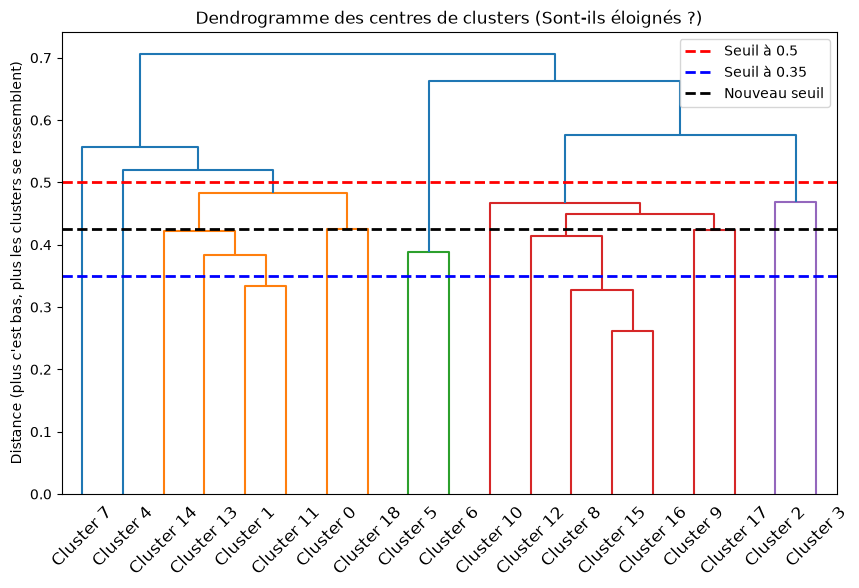

In [92]:
Z = linkage(kmeans.cluster_centers_, method='ward')

plt.figure(figsize=(10, 6))
plt.title("Dendrogramme des centres de clusters (Sont-ils éloignés ?)")
plt.ylabel("Distance (plus c'est bas, plus les clusters se ressemblent)")

# Affichage de l'arbre
dendrogram(Z, labels=[f"Cluster {i}" for i in range(k_final)], leaf_rotation=45)

plt.axhline(y=0.5, color='red', linestyle='--', linewidth=2, label='Seuil à 0.5')

plt.axhline(y=0.35, color='blue', linestyle='--', linewidth=2, label='Seuil à 0.35')

plt.axhline(y=(1-0.5-((0.5-0.35)/2)), color='black', linestyle='--', linewidth=2, label='Nouveau seuil')

plt.legend()

plt.show()

### Nouvelle conclusion

En regardant la distance entre les clusters, on voit que 19 clusters est trop élevé. En effet, Certains clusters se recoupent à des distances trop basse (En dessous de 0.35 pour trois d'entre eux) signfiant qu'ils ont un sens bien trop proche. 


En traçant deux seuils au dessus et en dessous du moment où beaucoup de clusters se recoupent. Et ensuite en traçant le centre de ces deux seuil. On peut obtenir un nouveau nombre de clusters équivalant à 13.

Ce nouveau nombre semble déjà beaucoup plus cohérant avec notre problème initial. 13 groupes de patients pour de symptômes semblent potentiellement beaucoup plus efficaces et rapide à traiter. Nous décidons donc de partir sur ce nouveau nombre de clusters.

In [93]:
nvx_nbr_clusters = 13

## Kmeans Modele

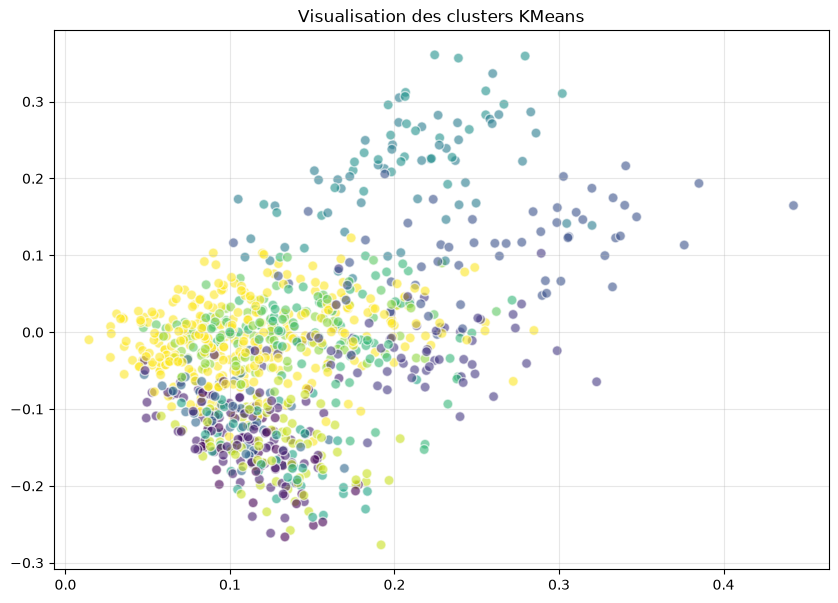

In [94]:
kmeans_final = KMeans(n_clusters=nvx_nbr_clusters, random_state=42, n_init="auto")
clusters = kmeans_final.fit_predict(X_reduced_final)

# Préparation de la visualisation 2D
x_axis = X_reduced_final[:, 0]
y_axis = X_reduced_final[:, 1]

plt.figure(figsize=(10, 7))

scatter = plt.scatter(x_axis, y_axis, c=clusters, cmap='viridis', alpha=0.6, edgecolors='w', s=50)
centres_2d = kmeans_final.cluster_centers_[:, :2]

plt.title("Visualisation des clusters KMeans")
plt.grid(True, alpha=0.3)
plt.show()

## Clustering Hiérarchique Agglomératif

Silhouette Score (Agglomerative) : 0.0409


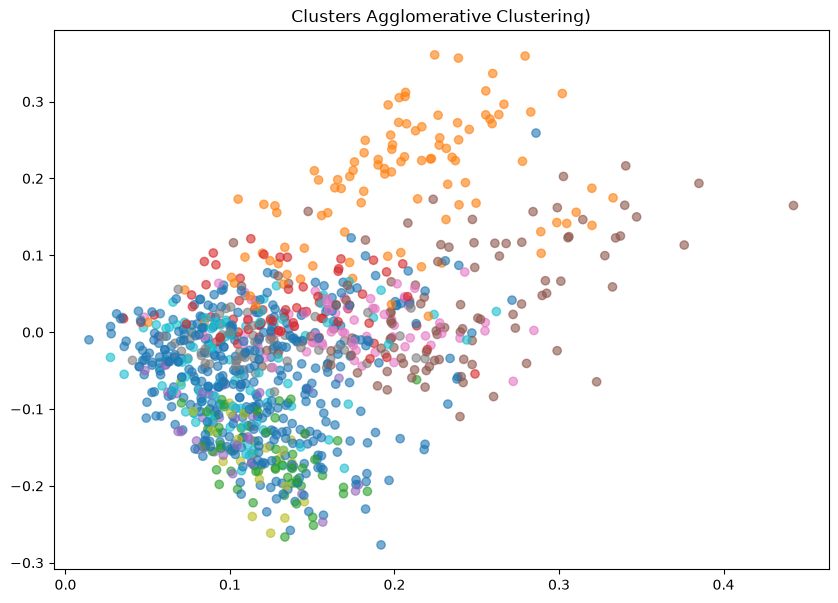

In [95]:
modele_agglo = AgglomerativeClustering(n_clusters=nvx_nbr_clusters, linkage='ward')

# Entrainement du modèle
labels_agglo = modele_agglo.fit_predict(X_reduced_final)

score = silhouette_score(X_reduced_final, labels_agglo)
print(f"Silhouette Score (Agglomerative) : {score:.4f}")

plt.figure(figsize=(10, 7))
plt.scatter(X_reduced_final[:, 0], X_reduced_final[:, 1], c=labels_agglo, cmap='tab10', alpha=0.6)
plt.title("Clusters Agglomerative Clustering)")
plt.show()

## Gausse Mélange Modèle

Silhouette Score (GMM) : 0.0561


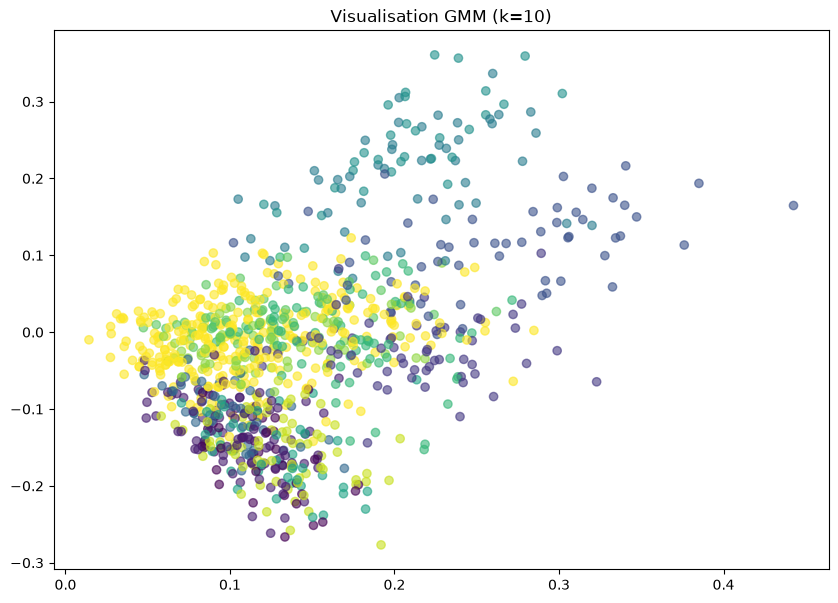

In [96]:
gmm = GaussianMixture(n_components=nvx_nbr_clusters, random_state=42).fit(X_reduced_final)
labels_gmm = gmm.predict(X_reduced_final)

print(f"Silhouette Score (GMM) : {silhouette_score(X_reduced_final, labels_gmm):.4f}")
plt.figure(figsize=(10, 7))
plt.scatter(X_reduced_final[:, 0], X_reduced_final[:, 1], c=labels_gmm, cmap='viridis', alpha=0.6)
plt.title("Visualisation GMM (k=10)")
plt.show()

## DBSCAN


DBSCAN : 0 clusters trouvés, 1011 points de bruit


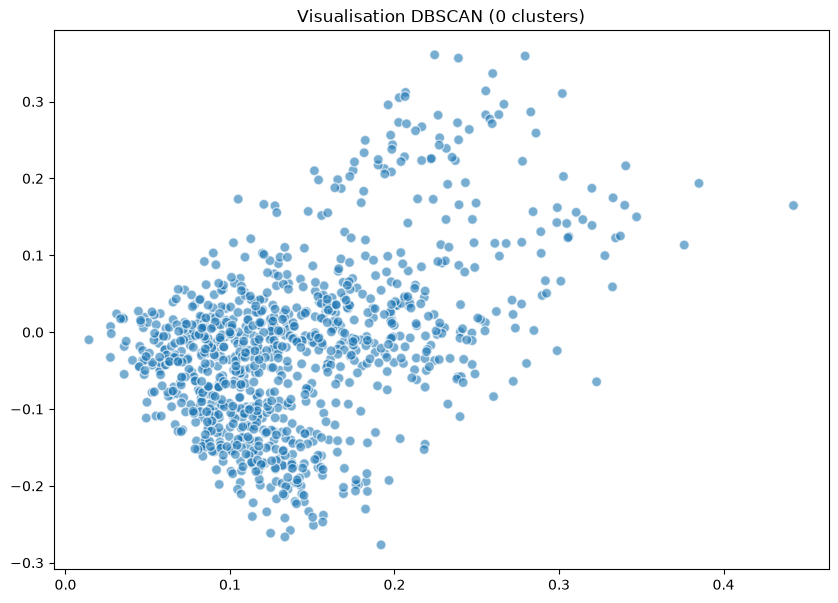

In [97]:
dbscan = DBSCAN(eps=0.1, min_samples=4)
labels_dbscan = dbscan.fit_predict(X_reduced_final)

n_clusters = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise = list(labels_dbscan).count(-1)
print(f"DBSCAN : {n_clusters} clusters trouvés, {n_noise} points de bruit")

plt.figure(figsize=(10, 7))
plt.scatter(X_reduced_final[:, 0], X_reduced_final[:, 1], c=labels_dbscan, cmap='tab20', alpha=0.6, edgecolors='w', s=50)
plt.title(f"Visualisation DBSCAN ({n_clusters} clusters)")
plt.show()

## comparaison 4 modèles


In [98]:
modeles = {"KMeans": clusters, "Agglomerative": labels_agglo, "GMM": labels_gmm, "DBSCAN": labels_dbscan}
print("Comparaison des modèles de clustering :\n")

for nom, labels in modeles.items():
    # dbscan considère -1 comme du bruit et donc on l'exclut du calcul
    if nom == "DBSCAN":
        mask = labels != -1
        X_calc = X_reduced_final[mask]
        labels_calc = labels[mask]

        nb_clusters = len(set(labels)) - 1
        nb_bruit = sum(labels == -1)

    else:
        X_calc = X_reduced_final
        labels_calc = labels
        nb_clusters = len(set(labels))
        nb_bruit = 0

    # Le score de silhouette nécessite au moins 2 clusters
    if nb_clusters > 1:
        score = silhouette_score(X_calc, labels_calc)
    else:
        score = 0.0

    print(f"{nom:<15} | Score : {score:.4f} " f"| Clusters : {nb_clusters} " f"| Bruit : {nb_bruit}")

Comparaison des modèles de clustering :

KMeans          | Score : 0.0561 | Clusters : 13 | Bruit : 0
Agglomerative   | Score : 0.0409 | Clusters : 13 | Bruit : 0
GMM             | Score : 0.0561 | Clusters : 13 | Bruit : 0
DBSCAN          | Score : 0.0000 | Clusters : 0 | Bruit : 1011
